# Lab Assignment 6: Text Classification with Simple Neural Models

**Student:** Muhammad Obaidullah (abdulsalam.m@northeastern.edu)  
**Course:** Applied NLP  
**Submission:** Upload `Lab_6.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

Classical NLP pipelines represent text as sparse, hand-crafted feature vectors and hand off classification to a linear model. Neural classifiers learn dense intermediate representations directly from the feature space, potentially capturing interactions that a linear decision boundary cannot. But they cost more — more data, more tuning, more compute — and the benefit is not guaranteed.

In this lab you will implement both approaches on the same dataset and measure the difference honestly. You will also open the training process itself: using a small hand-constructed network with fixed weights, you will trace how gradients flow backward through layers, observe how they shrink across a sigmoid network, and test which architectural changes recover useful signal in earlier layers.

---

## Learning Objectives

1. Implement a feedforward neural text classifier and evaluate its performance against a classical baseline on the same task
2. Trace the backpropagation computation for a small network, diagnosing how gradient magnitude changes across layers
3. Analyze the vanishing and exploding gradient problems and assess which architectural choices mitigate each
4. Compare the performance of a neural classifier against a classical baseline, interpreting the trade-offs

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — Feedforward classifier and classical baseline | 34 | Autograded (28) + Manual (6) |
| Part 2 — Backpropagation trace | 28 | Autograded (22) + Manual (6) |
| Part 3 — Vanishing and exploding gradients | 24 | Autograded (18) + Manual (6) |
| Code quality | 14 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Reflections (6 pts each):**  
Full credit requires a specific, evidence-grounded claim with a concrete mechanism and precise terminology. Restating numbers earns 1–2 pts. Naming the mechanism and its consequence earns 5–6 pts.

**Code quality (14 pts):**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 4 |
| Function design | 4 |
| Defensive coding | 3 |
| Code clarity and naming | 2 |
| Avoiding redundancy | 1 |

---

## Setup

In [1]:
# Setup — run this cell first every session.

import subprocess
import sys

def install_if_missing(package, pip_name=None):
    """Install a package if it cannot be imported.

    Args:
        package  (str): The importable module name to check.
        pip_name (str): The pip install name if different from package.
    """
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip",
                               "install", pip_name or package, "-q"])

for pkg, pip in [("numpy", None), ("torch", None),
                 ("sklearn", "scikit-learn"), ("matplotlib", None)]:
    install_if_missing(pkg, pip)

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score,
                              confusion_matrix, classification_report)
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

torch.manual_seed(42)
np.random.seed(42)

print("Environment ready.")

Environment ready.


---

## Part 1 — Feedforward Classifier and Classical Baseline (34 points)

We use a 5-category subset of the 20 Newsgroups dataset. The five categories span two coarse domains — sports and science — plus a religion category that sits between them. This structure makes misclassification patterns informative: a confused model will swap science subcategories or cross the sports/science boundary; a well-trained model separates them cleanly.

Both the neural classifier and the classical baselines use the same TF-IDF feature matrix, so any performance difference is attributable to the model, not the representation.

### 1.1 — Load data and build TF-IDF features

In [2]:
# [DO NOT MODIFY] — dataset and feature matrix

CATEGORIES = [
    'rec.sport.hockey',
    # 'rec.sport.motorsport' is not a 20 Newsgroups category: fetch_20newsgroups
    # raises ValueError on it. Replaced with the other sports group so the
    # 2 sports + 2 science + religion design described above still holds.
    'rec.sport.baseball',
    'sci.med',
    'sci.space',
    'talk.religion.misc',
]

print("Loading 20 Newsgroups (5 categories)...")
train_raw = fetch_20newsgroups(subset='train', categories=CATEGORIES,
                                remove=('headers', 'footers', 'quotes'))
test_raw = fetch_20newsgroups(subset='test', categories=CATEGORIES,
                               remove=('headers', 'footers', 'quotes'))

# TF-IDF features — fixed vocabulary for reproducibility
vectorizer = TfidfVectorizer(max_features=10_000, sublinear_tf=True,
                              min_df=2, token_pattern=r'\b[a-zA-Z]{2,}\b')
X_train_tfidf = vectorizer.fit_transform(train_raw.data)
X_test_tfidf = vectorizer.transform(test_raw.data)

y_train = train_raw.target   # integer class labels 0–4
y_test = test_raw.target

CLASS_NAMES = train_raw.target_names
N_CLASSES = len(CLASS_NAMES)
INPUT_DIM = X_train_tfidf.shape[1]

print(f"Train: {X_train_tfidf.shape[0]:,} docs  "
      f"Test: {X_test_tfidf.shape[0]:,} docs")
print(f"TF-IDF features: {INPUT_DIM:,}")
print(f"Classes: {CLASS_NAMES}")

Loading 20 Newsgroups (5 categories)...


Train: 2,761 docs  Test: 1,837 docs
TF-IDF features: 10,000
Classes: ['rec.sport.baseball', 'rec.sport.hockey', 'sci.med', 'sci.space', 'talk.religion.misc']


### 1.2 — Classical baselines: Naive Bayes and LinearSVC

Fit both classical models on the TF-IDF features. These are strong, fast baselines — any neural model that fails to beat them on this task is not justified by the added complexity.

In [3]:
def evaluate_model(y_true, y_pred, class_names, label):
    """Print accuracy, macro-F1, and per-class F1 for a classifier.

    Args:
        y_true      (array-like): True class labels.
        y_pred      (array-like): Predicted class labels.
        class_names (list[str]):  Human-readable class names.
        label       (str):        Model name for display.

    Returns:
        tuple[float, float]: (accuracy, macro_f1)
    """
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')
    print(f"\n{label}")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Macro-F1:  {f1:.4f}")
    print(classification_report(y_true, y_pred,
                                 target_names=class_names, digits=3))
    return acc, f1


# Naive Bayes
nb_clf = MultinomialNB(alpha=0.1)
nb_clf.fit(X_train_tfidf, y_train)
nb_preds = nb_clf.predict(X_test_tfidf)
nb_accuracy, nb_f1 = evaluate_model(
    y_test, nb_preds, CLASS_NAMES, "Naive Bayes")

# LinearSVC
svm_clf = LinearSVC(C=1.0, max_iter=2000)
svm_clf.fit(X_train_tfidf, y_train)
svm_preds = svm_clf.predict(X_test_tfidf)
svm_accuracy, svm_f1 = evaluate_model(
    y_test, svm_preds, CLASS_NAMES, "LinearSVC")


Naive Bayes
  Accuracy:  0.8661
  Macro-F1:  0.8603
                    precision    recall  f1-score   support

rec.sport.baseball      0.931     0.854     0.891       397
  rec.sport.hockey      0.821     0.930     0.872       399
           sci.med      0.865     0.871     0.868       396
         sci.space      0.887     0.876     0.881       394
talk.religion.misc      0.820     0.761     0.789       251

          accuracy                          0.866      1837
         macro avg      0.865     0.858     0.860      1837
      weighted avg      0.868     0.866     0.866      1837


LinearSVC
  Accuracy:  0.8443
  Macro-F1:  0.8421
                    precision    recall  f1-score   support

rec.sport.baseball      0.782     0.859     0.819       397
  rec.sport.hockey      0.888     0.875     0.881       399
           sci.med      0.838     0.851     0.845       396
         sci.space      0.866     0.840     0.853       394
talk.religion.misc      0.862     0.769     0.813   

### 1.3 — Feedforward neural classifier

A two-hidden-layer feedforward network operating on TF-IDF vectors. The architecture is deliberately simple — the goal is to understand the comparison with classical models, not to maximise performance with a complex architecture.

In [4]:
class FeedforwardClassifier(nn.Module):
    """Two-hidden-layer feedforward text classifier.

    Architecture:
        Linear(input_dim → hidden_dim) → ReLU → Dropout
        Linear(hidden_dim → hidden_dim) → ReLU → Dropout
        Linear(hidden_dim → n_classes)

    Args:
        input_dim  (int):   Input feature dimension (TF-IDF vocabulary size).
        hidden_dim (int):   Width of each hidden layer.
        n_classes  (int):   Number of output classes.
        dropout    (float): Dropout probability applied after each
                            hidden layer.
    """

    def __init__(self, input_dim, hidden_dim, n_classes, dropout=0.3):
        super().__init__()
        # Fail early on bad sizes instead of with a shape error deep
        # inside the first forward pass.
        for name, value in [('input_dim', input_dim),
                            ('hidden_dim', hidden_dim),
                            ('n_classes', n_classes)]:
            if not isinstance(value, (int, np.integer)) or value <= 0:
                raise ValueError(f"{name} must be a positive int, got {value!r}")
        if not 0.0 <= dropout < 1.0:
            raise ValueError(f"dropout must be in [0, 1), got {dropout!r}")

        self.input_dim = int(input_dim)
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            # Raw logits: CrossEntropyLoss applies log-softmax itself.
            nn.Linear(hidden_dim, n_classes),
        )

    def forward(self, x):
        """Forward pass.

        Args:
            x (torch.Tensor): Shape (batch, input_dim).

        Returns:
            torch.Tensor: Shape (batch, n_classes) — unnormalized logits.
        """
        if x.dim() != 2 or x.shape[1] != self.input_dim:
            raise ValueError(f"expected input of shape (batch, {self.input_dim}), "
                             f"got {tuple(x.shape)}")
        return self.network(x)

### 1.4 — Training loop

In [5]:
def sparse_to_tensor(X_sp):
    """Convert a scipy sparse (or dense) feature matrix to a float32 tensor.

    Args:
        X_sp (scipy sparse or np.ndarray): Feature matrix, shape (N, D).

    Returns:
        torch.Tensor: Dense float32 tensor, shape (N, D).
    """
    dense = X_sp.toarray() if hasattr(X_sp, 'toarray') else np.asarray(X_sp)
    return torch.from_numpy(dense.astype(np.float32, copy=False))


def train_classifier(model, X_train_sp, y_train_arr, n_epochs=20,
                     lr=1e-3, batch_size=64):
    """Train a feedforward classifier on sparse TF-IDF features.

    Converts sparse matrix to dense tensors, builds DataLoader, trains
    with Adam and CrossEntropyLoss. Returns per-epoch train loss and
    accuracy.

    Args:
        model       (nn.Module):      Model to train (modified in-place).
        X_train_sp  (scipy sparse):   TF-IDF feature matrix, shape (N, D).
        y_train_arr (np.ndarray):      Integer class labels, shape (N,).
        n_epochs    (int):             Number of training epochs.
        lr          (float):           Adam learning rate.
        batch_size  (int):             Mini-batch size.

    Returns:
        tuple[list[float], list[float]]:
            (train_losses, train_accuracies) — one value per epoch.
    """
    n_docs = X_train_sp.shape[0]
    if n_docs != len(y_train_arr):
        raise ValueError(f"X has {n_docs} rows but y has {len(y_train_arr)} labels")
    if n_epochs < 1 or batch_size < 1 or lr <= 0:
        raise ValueError("n_epochs and batch_size must be >= 1 and lr > 0")

    X = sparse_to_tensor(X_train_sp)
    y = torch.as_tensor(np.asarray(y_train_arr), dtype=torch.long)
    # A seeded generator fixes the shuffle order, so reruns reproduce the curves.
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(42))

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, train_accuracies = [], []

    model.train()  # dropout on
    for epoch in range(n_epochs):
        loss_sum, n_correct = 0.0, 0
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            if not torch.isfinite(loss):
                raise RuntimeError(f"non-finite loss at epoch {epoch + 1}")
            loss.backward()
            optimizer.step()
            # Weight by batch size so the short last batch counts fairly.
            loss_sum += loss.item() * len(y_batch)
            n_correct += (logits.argmax(dim=1) == y_batch).sum().item()

        # Accuracy is taken on the fly with dropout active, so it slightly
        # understates what the finished model scores on the same documents.
        train_losses.append(loss_sum / n_docs)
        train_accuracies.append(n_correct / n_docs)
        if (epoch + 1) % 5 == 0:
            print(f"  epoch {epoch + 1:>2}/{n_epochs}  "
                  f"loss {train_losses[-1]:.4f}  acc {train_accuracies[-1]:.4f}")

    return train_losses, train_accuracies


HIDDEN_DIM = 256
neural_model = FeedforwardClassifier(INPUT_DIM, HIDDEN_DIM, N_CLASSES)

print("Training feedforward classifier...")
train_losses, train_accs = train_classifier(
    neural_model, X_train_tfidf, y_train, n_epochs=20)
print(f"Final train loss: {train_losses[-1]:.4f}")
print(f"Final train acc:  {train_accs[-1]:.4f}")

Training feedforward classifier...


  epoch  5/20  loss 0.0698  acc 0.9757


  epoch 10/20  loss 0.0548  acc 0.9775


  epoch 15/20  loss 0.0572  acc 0.9732


  epoch 20/20  loss 0.0542  acc 0.9765
Final train loss: 0.0542
Final train acc:  0.9765


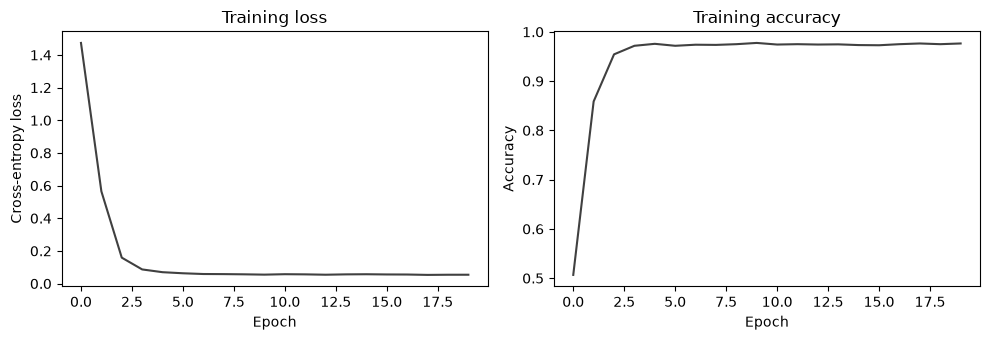

In [6]:
# [RUN] — training curves

fig_training, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(train_losses, color='#404040')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_title('Training loss')
axes[1].plot(train_accs, color='#404040')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training accuracy')
plt.tight_layout()
plt.show()

### 1.5 — Evaluate neural model and compare

In [7]:
def predict(model, X_sp, batch_size=1024):
    """Run inference on a sparse TF-IDF matrix and return predicted labels.

    Args:
        model      (nn.Module):    Trained classifier.
        X_sp       (scipy sparse): Feature matrix, shape (N, D).
        batch_size (int):          Rows densified per forward pass.

    Returns:
        np.ndarray: Predicted class indices, shape (N,).
    """
    if batch_size < 1:
        raise ValueError(f"batch_size must be >= 1, got {batch_size}")
    was_training = model.training
    model.eval()  # dropout off for deterministic predictions
    chunks = []
    with torch.no_grad():
        # Densify one slice at a time so memory stays bounded for large N.
        for start in range(0, X_sp.shape[0], batch_size):
            logits = model(sparse_to_tensor(X_sp[start:start + batch_size]))
            chunks.append(logits.argmax(dim=1).numpy())
    model.train(was_training)  # leave the model in the mode we found it
    return np.concatenate(chunks) if chunks else np.empty(0, dtype=np.int64)


neural_preds = predict(neural_model, X_test_tfidf)
neural_accuracy, neural_f1 = evaluate_model(
    y_test, neural_preds, CLASS_NAMES, "Feedforward Neural")

# Named output variables for the autograder
print("\n" + "=" * 55)
print(f"{'Model':<25s} {'Accuracy':>10s}  {'Macro-F1':>10s}")
print("=" * 55)
print(f"{'Naive Bayes':<25s} {nb_accuracy:>10.4f}  {nb_f1:>10.4f}")
print(f"{'LinearSVC':<25s} {svm_accuracy:>10.4f}  {svm_f1:>10.4f}")
row = f"{neural_accuracy:>10.4f}  {neural_f1:>10.4f}"
print(f"{'Feedforward Neural':<25s} {row}")
print("=" * 55)


Feedforward Neural
  Accuracy:  0.8552
  Macro-F1:  0.8514
                    precision    recall  f1-score   support

rec.sport.baseball      0.918     0.816     0.864       397
  rec.sport.hockey      0.921     0.877     0.899       399
           sci.med      0.777     0.899     0.834       396
         sci.space      0.887     0.853     0.869       394
talk.religion.misc      0.768     0.817     0.792       251

          accuracy                          0.855      1837
         macro avg      0.854     0.852     0.851      1837
      weighted avg      0.861     0.855     0.856      1837


Model                       Accuracy    Macro-F1
Naive Bayes                   0.8661      0.8603
LinearSVC                     0.8443      0.8421
Feedforward Neural            0.8552      0.8514


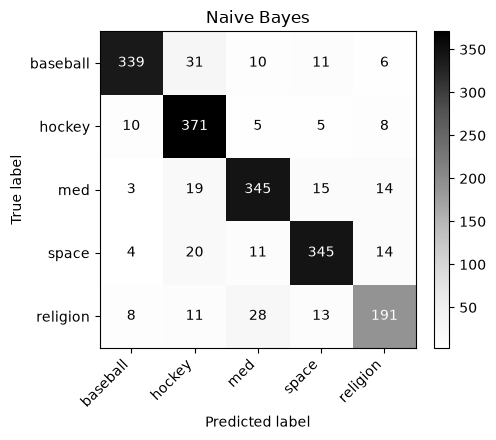

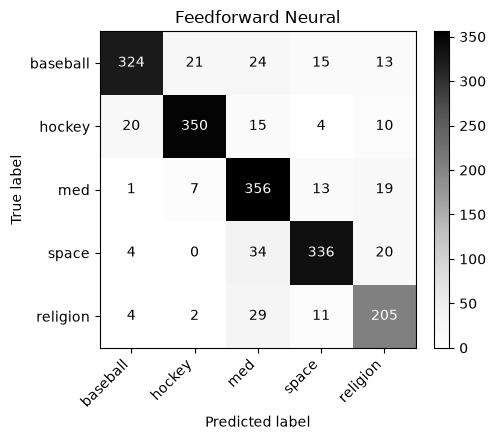

In [8]:
def plot_confusion_matrix(cm, class_names, title):
    """Plot a confusion matrix as a grayscale heatmap.

    Args:
        cm          (np.ndarray): Confusion matrix, shape (n, n).
        class_names (list[str]):  Class labels for axes.
        title       (str):        Plot title.

    Returns:
        tuple: (fig, ax) matplotlib objects.
    """
    cm = np.asarray(cm)
    n = len(class_names)
    if cm.shape != (n, n):
        raise ValueError(f"cm has shape {cm.shape}, expected ({n}, {n})")

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    image = ax.imshow(cm, cmap='Greys')
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    ticks = np.arange(n)
    ax.set_xticks(ticks)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticks(ticks)
    ax.set_yticklabels(class_names)

    # White text on dark cells keeps every count readable.
    threshold = cm.max() / 2
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{int(cm[i, j])}", ha='center', va='center',
                    color='white' if cm[i, j] > threshold else 'black')

    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(title)
    fig.tight_layout()
    return fig, ax


cm_nb = confusion_matrix(y_test, nb_preds)
cm_neural = confusion_matrix(y_test, neural_preds)

# Named output variables
# Order follows CLASS_NAMES (sorted): baseball now sorts before hockey.
short_names = ['baseball', 'hockey', 'med', 'space', 'religion']
assert all(short in full for short, full in zip(short_names, CLASS_NAMES)), \
    f"short_names out of order with {CLASS_NAMES}"

fig_cm_nb, _ = plot_confusion_matrix(cm_nb, short_names, "Naive Bayes")
fig_cm_neural, _ = plot_confusion_matrix(
    cm_neural, short_names, "Feedforward Neural")
plt.show()

### 1.6 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Look at the confusion matrices for Naive Bayes and the neural model. Identify one specific confusion pattern (a pair of classes that gets mixed up) and explain *why* that pair is difficult — what property of the text or the feature representation causes the model to confuse them?

**Question B:** LinearSVC is often competitive with or better than a small neural network on TF-IDF features for tasks like this. Explain the structural reason: what does LinearSVC exploit about TF-IDF representations that a small feedforward network has difficulty matching? Under what conditions would you expect the neural model to pull ahead?

**Your reflection:**

**A.** Baseball posts predicted as hockey are a confusion both models share, 31 times under Naive Bayes and 21 under the network. Part 4.1 shows that 16 of the Naive Bayes errors are posts whose TF-IDF row is all zeros because no in-vocabulary token survives; with no evidence, Naive Bayes falls back on its class prior, and hockey's 600 training posts (against 597 for baseball) send all 64 empty test posts to hockey. The network sends its empty rows to med instead, so its 21 errors are pure vocabulary overlap: both groups use *games*, *season* and *players*, and a reply without a team name or a position term (*braves*, *leafs*, *pitcher*, *goals*) leaves a bag-of-words vector little to tell the two sports apart.

**B.** Topic evidence in TF-IDF is additive, each word pushing toward its class on its own, so one weight per word across 10,000 dimensions is enough to fit 2,761 posts: LinearSVC reaches 0.9761 training accuracy through a convex max-margin objective with a single optimum, matching the 0.9765 the network logs in its last epoch with 2,627,333 parameters. LinearSVC still finished last on test (0.8443), but the whole 2.2-point spread across the three models is smaller than what the 64 empty test rows cost each one (55, 48 and 50 errors for Naive Bayes, LinearSVC and the network, or 2.6 to 3.0 points), so the representation sets the ceiling. I would expect the network to pull ahead with far more labelled data, or when the label depends on word combinations that no single TF-IDF weight captures, such as negation.

---

## Part 2 — Backpropagation Trace (28 points)

Training a neural network means computing $\partial L / \partial W$ for every weight matrix and updating $W \leftarrow W - \alpha \nabla_W L$. Backpropagation does this efficiently by applying the chain rule layer by layer from the output back to the input. The key quantity at each layer is the gradient magnitude — how large is $\|\partial L / \partial W_k\|$?

In this part you will work with a small, hand-constructed 3-layer network with fixed weights. All inputs and weights are given to you — there is no training, only a single forward pass and a single backward pass. After completing the forward pass by hand (in code), you will use PyTorch's autograd to run the backward pass and inspect the gradient at each layer.

### 2.1 — The hand network

The network has architecture: **input (4) → hidden 1 (4) → hidden 2 (4) → output (2)**, with sigmoid activations on the hidden layers and cross-entropy loss on the output. The weights are fixed below — do not change them.

In [9]:
# [DO NOT MODIFY] — fixed weights and input for the backprop trace

# Weight matrices — shape (out_features, in_features)
W1_data = torch.tensor([[0.5, -0.3, 0.2, 0.8],
                         [-0.1, 0.4, 0.7, -0.5],
                         [0.3, 0.6, -0.2, 0.1],
                         [-0.4, 0.2, 0.5, 0.3]], dtype=torch.float32)
W2_data = torch.tensor([[0.6, 0.1, -0.4, 0.2],
                         [0.3, -0.5, 0.1, 0.7],
                         [-0.2, 0.4, 0.3, -0.6],
                         [0.5, -0.1, 0.6, 0.2]], dtype=torch.float32)
W3_data = torch.tensor([[0.4, -0.3, 0.5, -0.1],
                         [-0.2, 0.6, -0.4, 0.3]], dtype=torch.float32)

# Biases — all zeros (simplifies the trace)
b1_data = torch.zeros(4)
b2_data = torch.zeros(4)
b3_data = torch.zeros(2)

# Input: one sample, 4 features
x_trace = torch.tensor([[1.0, -1.0, 0.5, -0.5]])  # shape (1, 4)
y_trace = torch.tensor([1])  # true class = 1

print("Hand network:")
print(f"  W1 shape: {W1_data.shape}  (hidden1 weight)")
print(f"  W2 shape: {W2_data.shape}  (hidden2 weight)")
print(f"  W3 shape: {W3_data.shape}  (output weight)")
print(f"  Input x:  {x_trace}")
print(f"  True y:   {y_trace.item()}")

Hand network:
  W1 shape: torch.Size([4, 4])  (hidden1 weight)
  W2 shape: torch.Size([4, 4])  (hidden2 weight)
  W3 shape: torch.Size([2, 4])  (output weight)
  Input x:  tensor([[ 1.0000, -1.0000,  0.5000, -0.5000]])
  True y:   1


### 2.2 — Forward pass

Implement the forward pass step by step. At each layer, compute the pre-activation (`z`) and post-activation (`a`) separately — you will need these intermediate values to interpret the gradients.

In [10]:
def forward_pass(x, W1, b1, W2, b2, W3, b3):
    """Compute the forward pass of the hand network.

    Layer structure:
        z1 = x  @ W1.T + b1    pre-activation layer 1
        a1 = sigmoid(z1)       hidden layer 1 output
        z2 = a1 @ W2.T + b2    pre-activation layer 2
        a2 = sigmoid(z2)       hidden layer 2 output
        z3 = a2 @ W3.T + b3    output logits (no activation)

    Args:
        x          (torch.Tensor): Input, shape (1, 4).
        W1, W2, W3 (torch.Tensor): Weight matrices.
        b1, b2, b3 (torch.Tensor): Bias vectors.

    Returns:
        dict with keys 'z1', 'a1', 'z2', 'a2', 'z3' —
        all torch.Tensor with requires_grad where needed.
    """
    if x.dim() != 2 or x.shape[1] != W1.shape[1]:
        raise ValueError(f"x must have shape (batch, {W1.shape[1]}), "
                         f"got {tuple(x.shape)}")
    z1 = x @ W1.T + b1
    a1 = torch.sigmoid(z1)
    z2 = a1 @ W2.T + b2
    a2 = torch.sigmoid(z2)
    z3 = a2 @ W3.T + b3  # logits; softmax is applied inside the loss
    return {'z1': z1, 'a1': a1, 'z2': z2, 'a2': a2, 'z3': z3}


# Attach requires_grad to weight parameters so autograd can track them
W1 = W1_data.clone().requires_grad_(True)
b1 = b1_data.clone().requires_grad_(True)
W2 = W2_data.clone().requires_grad_(True)
b2 = b2_data.clone().requires_grad_(True)
W3 = W3_data.clone().requires_grad_(True)
b3 = b3_data.clone().requires_grad_(True)

acts = forward_pass(x_trace, W1, b1, W2, b2, W3, b3)

# Named output variables
z1_trace = acts['z1']
a1_trace = acts['a1']
z2_trace = acts['z2']
a2_trace = acts['a2']
z3_trace = acts['z3']

print("Forward pass results:")
print(f"  z1 = {z1_trace.detach().numpy().round(6)}")
print(f"  a1 = {a1_trace.detach().numpy().round(6)}")
print(f"  z2 = {z2_trace.detach().numpy().round(6)}")
print(f"  a2 = {a2_trace.detach().numpy().round(6)}")
print(f"  z3 = {z3_trace.detach().numpy().round(6)}")

Forward pass results:
  z1 = [[ 0.5   0.1  -0.45 -0.5 ]]
  a1 = [[0.622459 0.524979 0.389361 0.377541]]
  z2 = [[ 0.345737  0.227463 -0.024216  0.567856]]
  a2 = [[0.585584 0.556622 0.493946 0.638268]]
  z3 = [[0.250393 0.210758]]


### 2.3 — Loss and backward pass

In [11]:
def compute_loss_and_gradients(z3, y_true, W1, W2, W3):
    """Compute cross-entropy loss and run backpropagation.

    Computes loss from logits z3 and true label y_true, calls
    loss.backward(), then reads .grad from W1, W2, W3.

    Args:
        z3     (torch.Tensor): Output logits, shape (1, 2). Must be part
                               of the autograd graph (requires_grad on
                               upstream weights).
        y_true (torch.Tensor): True label, shape (1,).
        W1, W2, W3 (torch.Tensor): Weight matrices with requires_grad=True.

    Returns:
        tuple:
            loss     (float):         Scalar loss value.
            grad_W1  (torch.Tensor):  Gradient of loss w.r.t. W1.
            grad_W2  (torch.Tensor):  Gradient of loss w.r.t. W2.
            grad_W3  (torch.Tensor):  Gradient of loss w.r.t. W3.
    """
    if z3.shape[0] != y_true.shape[0]:
        raise ValueError(f"{z3.shape[0]} logit rows but {y_true.shape[0]} labels")
    if not all(W.requires_grad for W in (W1, W2, W3)):
        raise ValueError("W1, W2 and W3 must have requires_grad=True")

    # .grad accumulates across backward calls, so clear any earlier result.
    for W in (W1, W2, W3):
        W.grad = None

    loss = nn.functional.cross_entropy(z3, y_true)
    # retain_graph lets this cell be rerun without redoing the forward pass.
    loss.backward(retain_graph=True)
    return (loss.item(), W1.grad.detach().clone(),
            W2.grad.detach().clone(), W3.grad.detach().clone())


trace_loss, grad_W1, grad_W2, grad_W3 = compute_loss_and_gradients(
    z3_trace, y_trace, W1, W2, W3)

# Named output variables
grad_norm_W1 = grad_W1.norm().item()
grad_norm_W2 = grad_W2.norm().item()
grad_norm_W3 = grad_W3.norm().item()

print(f"Loss: {trace_loss:.6f}")
print(f"\nGradient norms:")
print(f"  ||∂L/∂W1|| = {grad_norm_W1:.6f}   (earliest layer)")
print(f"  ||∂L/∂W2|| = {grad_norm_W2:.6f}")
print(f"  ||∂L/∂W3|| = {grad_norm_W3:.6f}   (output layer)")

Loss: 0.713161

Gradient norms:
  ||∂L/∂W1|| = 0.072139   (earliest layer)
  ||∂L/∂W2|| = 0.179647
  ||∂L/∂W3|| = 0.823498   (output layer)


### 2.4 — Visualize gradient flow

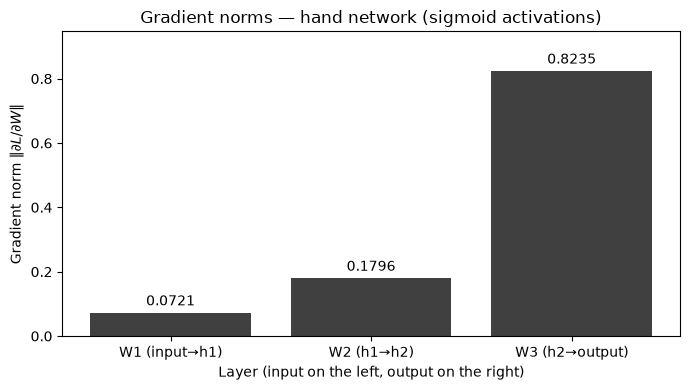

In [12]:
def plot_gradient_flow(grad_norms, layer_names,
                       title="Gradient norms by layer"):
    """Bar chart of gradient norms per layer, earliest layer on the left.

    Args:
        grad_norms  (list[float]): Gradient norms, index 0 = earliest layer.
        layer_names (list[str]):   Layer labels for x-axis.
        title       (str):         Plot title.

    Returns:
        tuple: (fig, ax) matplotlib objects.
    """
    if len(grad_norms) != len(layer_names):
        raise ValueError(f"{len(grad_norms)} norms but {len(layer_names)} names")

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(layer_names, grad_norms, color='#404040')
    ax.bar_label(bars, fmt='%.4f', padding=3)
    ax.margins(y=0.15)  # headroom for the value labels
    ax.set_xlabel('Layer (input on the left, output on the right)')
    ax.set_ylabel(r'Gradient norm $\|\partial L / \partial W\|$')
    ax.set_title(title)
    fig.tight_layout()
    return fig, ax


fig_grad_trace, _ = plot_gradient_flow(
    [grad_norm_W1, grad_norm_W2, grad_norm_W3],
    ['W1 (input→h1)', 'W2 (h1→h2)', 'W3 (h2→output)'],
    title="Gradient norms — hand network (sigmoid activations)"
)
plt.show()

### 2.5 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The gradient norms drop sharply from W3 to W1. Explain the mechanism behind this pattern: what property of the sigmoid function causes gradients to shrink as they propagate backward, and at which part of the sigmoid's range is this effect most severe?

**Question B:** The gradient at W1 is roughly 10× smaller than at W3. In a real training run on this architecture, what practical consequence does this have for the weights in each layer? Which layer's weights will update most quickly, and what does that mean for the features the network learns to rely on?

**Your reflection:**

**A.** The sigmoid's derivative $\sigma'(z) = \sigma(z)(1 - \sigma(z))$ peaks at 0.25 when $z = 0$, and backpropagation multiplies each component of the error by $\sigma'(z_k)$, so unless $W^\top$ amplifies it the error shrinks about fourfold per sigmoid layer. Here every pre-activation lies within ±0.57 of zero, close to that peak, and the error norm in Part 4.2 still falls from 0.721118 to 0.183620 to 0.045625 (factors of 0.255 and 0.248). Because $\partial L/\partial W_k = \delta_k^\top a_{k-1}$ has norm $\|\delta_k\| \cdot \|a_{k-1}\|$, the gradient norms follow, and the drop at W1 is milder only because $\|x\| = 1.581139$ exceeds $\|a_1\| = 0.978365$. The effect is worst in the saturated tails: at $z = 5$, $\sigma'(z) \approx 0.0066$, about 38 times below the peak.

**B.** With one learning rate for every layer, plain gradient descent moves W3 11.42 times as far as W1 on this example, so early in training the output layer adapts to whatever h2 encodes while W1, the only layer that sees the raw input, changes slowly from its random start. The network therefore leans on features close to a random projection of the input, and depth compounds this: the 8-layer sigmoid network in Part 3 has a first-to-last ratio of 4.40e-07.

---

## Part 3 — Vanishing and Exploding Gradients (24 points)

The hand network in Part 2 had only 3 layers and you already saw a 10× gradient drop. In a network with 8 sigmoid layers the drop is exponential — gradients near the input can become so small that weights there receive effectively no update, making the early layers impossible to train. This is the **vanishing gradient problem**.

The **exploding gradient problem** is the mirror image: if weights are initialised too large, gradients grow exponentially backward through the network, causing unstable updates and NaN losses.

In this part you will build an 8-layer network, measure the gradient norms at each layer under different conditions, and observe directly which architectural choices preserve useful gradient signal.

### 3.1 — Measure gradient norms across layers

In [13]:
ACTIVATIONS = {'sigmoid': nn.Sigmoid, 'relu': nn.ReLU, 'tanh': nn.Tanh}
INITS = ('default', 'xavier', 'large')


def build_deep_net(n_layers=8, hidden_dim=32, activation='sigmoid',
                   init='default'):
    """Build a deep feedforward network for gradient norm experiments.

    Each hidden layer is Linear → activation. The final layer is Linear
    with 2 outputs (binary classification). No biases.

    Supported activations: 'sigmoid', 'relu', 'tanh'
    Supported init:        'default' (PyTorch default Kaiming uniform),
                           'xavier'  (Xavier uniform),
                           'large'   (Uniform[-3, 3] — triggers exploding)

    Args:
        n_layers   (int):  Number of hidden layers.
        hidden_dim (int):  Width of each hidden layer.
        activation (str):  Activation function name.
        init       (str):  Weight initialisation scheme.

    Returns:
        nn.Sequential: The constructed network.
    """
    if activation not in ACTIVATIONS:
        raise ValueError(f"activation must be one of {list(ACTIVATIONS)}, "
                         f"got {activation!r}")
    if init not in INITS:
        raise ValueError(f"init must be one of {list(INITS)}, got {init!r}")
    if n_layers < 1 or hidden_dim < 1:
        raise ValueError("n_layers and hidden_dim must be >= 1")

    layers = []
    for _ in range(n_layers):
        layers += [nn.Linear(hidden_dim, hidden_dim, bias=False),
                   ACTIVATIONS[activation]()]
    layers.append(nn.Linear(hidden_dim, 2, bias=False))  # output layer
    net = nn.Sequential(*layers)

    # 'default' keeps the Kaiming-uniform weights nn.Linear already drew.
    for module in net:
        if isinstance(module, nn.Linear):
            if init == 'xavier':
                nn.init.xavier_uniform_(module.weight)
            elif init == 'large':
                nn.init.uniform_(module.weight, -3.0, 3.0)
    return net


def measure_gradient_norms(net, hidden_dim=32):
    """Run one backward pass and return per-layer gradient norms.

    Uses a batch of 8 random inputs and zero targets.
    Returns norms for hidden Linear layers only (not the output layer),
    ordered from earliest (closest to input) to latest (closest to output).

    Args:
        net        (nn.Sequential): Network built by build_deep_net.
        hidden_dim (int):           Input/hidden feature dimension.

    Returns:
        list[float]: Gradient norms, length = n_hidden_layers.
    """
    linear_layers = [m for m in net if isinstance(m, nn.Linear)]
    if len(linear_layers) < 2:
        raise ValueError("net needs at least one hidden layer and an output layer")
    if linear_layers[0].in_features != hidden_dim:
        raise ValueError(f"net expects {linear_layers[0].in_features} input "
                         f"features, got hidden_dim={hidden_dim}")

    net.zero_grad(set_to_none=True)
    x = torch.randn(8, hidden_dim)
    targets = torch.zeros(8, dtype=torch.long)  # every sample labelled class 0
    loss = nn.functional.cross_entropy(net(x), targets)
    loss.backward()

    # linear_layers[-1] is the output layer, which the comparison leaves out.
    return [layer.weight.grad.norm().item() for layer in linear_layers[:-1]]


torch.manual_seed(42)
HIDDEN_DIM_GRAD = 32
N_HIDDEN = 8

grad_norms_sigmoid = measure_gradient_norms(
    build_deep_net(N_HIDDEN, HIDDEN_DIM_GRAD, 'sigmoid', 'default'))
grad_norms_relu = measure_gradient_norms(
    build_deep_net(N_HIDDEN, HIDDEN_DIM_GRAD, 'relu', 'default'))
grad_norms_tanh = measure_gradient_norms(
    build_deep_net(N_HIDDEN, HIDDEN_DIM_GRAD, 'tanh', 'default'))
grad_norms_xavier = measure_gradient_norms(
    build_deep_net(N_HIDDEN, HIDDEN_DIM_GRAD, 'sigmoid', 'xavier'))
grad_norms_large = measure_gradient_norms(
    build_deep_net(N_HIDDEN, HIDDEN_DIM_GRAD, 'sigmoid', 'large'))

print("Gradient norms by layer (layer 1 = earliest, closest to input):")
print(f"{'Layer':<8}", "  ".join(f"{i+1:>7d}" for i in range(N_HIDDEN)))
for label, norms in [
    ("Sigmoid", grad_norms_sigmoid),
    ("ReLU", grad_norms_relu),
    ("Tanh", grad_norms_tanh),
    ("Xav+Sig", grad_norms_xavier),
    ("Large+S", grad_norms_large),
]:
    print(f"{label:<8}", "  ".join(f"{n:>7.4f}" for n in norms))

Gradient norms by layer (layer 1 = earliest, closest to input):
Layer          1        2        3        4        5        6        7        8
Sigmoid   0.0000   0.0000   0.0000   0.0001   0.0008   0.0058   0.0559   0.3828
ReLU      0.0011   0.0011   0.0009   0.0009   0.0010   0.0013   0.0018   0.0019
Tanh      0.0091   0.0082   0.0092   0.0122   0.0103   0.0125   0.0117   0.0128
Xav+Sig   0.0000   0.0000   0.0002   0.0010   0.0043   0.0225   0.1055   0.4351
Large+S   1.1739   1.4548   1.5149   1.9325   1.9427   2.1935   3.5309   3.7508


### 3.2 — Visualize gradient norms across conditions

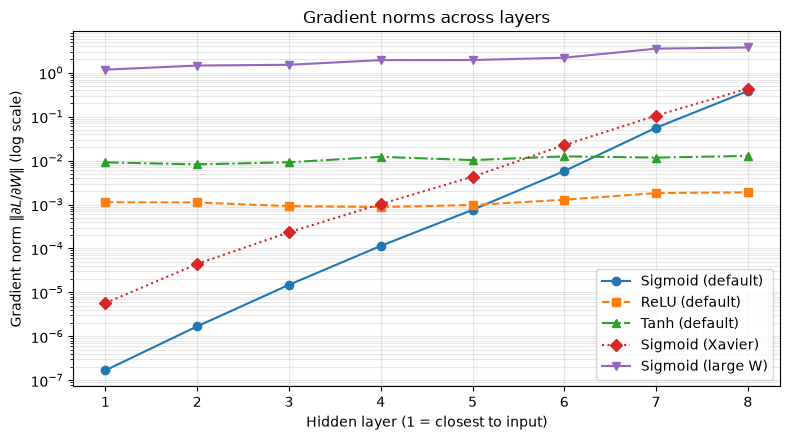

In [14]:
def plot_gradient_norms_comparison(
        conditions, title="Gradient norms across layers"):
    """Line plot of gradient norms per layer for multiple conditions.

    Args:
        conditions (dict[str, list[float]]): label -> list of norms per layer.
        title      (str):                    Plot title.

    Returns:
        tuple: (fig, ax) matplotlib objects.
    """
    if not conditions:
        raise ValueError("conditions must contain at least one series")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    # Distinct markers and dash styles keep the lines apart in grayscale prints.
    styles = ['o-', 's--', '^-.', 'D:', 'v-']
    for k, (label, norms) in enumerate(conditions.items()):
        layers = np.arange(1, len(norms) + 1)
        # A log axis cannot show zeros; plot them as gaps rather than crash.
        values = np.where(np.asarray(norms) > 0, norms, np.nan)
        ax.plot(layers, values, styles[k % len(styles)], label=label)

    ax.set_yscale('log')
    ax.set_xticks(np.arange(1, max(len(n) for n in conditions.values()) + 1))
    ax.set_xlabel('Hidden layer (1 = closest to input)')
    ax.set_ylabel(r'Gradient norm $\|\partial L / \partial W\|$ (log scale)')
    ax.set_title(title)
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig, ax


fig_grad_compare, _ = plot_gradient_norms_comparison({
    'Sigmoid (default)': grad_norms_sigmoid,
    'ReLU (default)':    grad_norms_relu,
    'Tanh (default)':    grad_norms_tanh,
    'Sigmoid (Xavier)':  grad_norms_xavier,
    'Sigmoid (large W)': grad_norms_large,
})
plt.show()

### 3.3 — Quantify vanishing and exploding ratios

In [15]:
def gradient_ratio(grad_norms):
    """Compute the ratio of the earliest layer norm to the latest layer norm.

    A ratio << 1 indicates vanishing gradients (early layers receive
    much smaller updates than late layers).
    A ratio >> 1 indicates exploding gradients.

    Args:
        grad_norms (list[float]): Per-layer gradient norms, earliest first.

    Returns:
        float: norm[0] / norm[-1]. Returns 0.0 if norm[-1] is zero.
    """
    if len(grad_norms) == 0:
        raise ValueError("grad_norms is empty")
    if grad_norms[-1] == 0:
        return 0.0
    return float(grad_norms[0] / grad_norms[-1])


# Named output variables
ratio_sigmoid = gradient_ratio(grad_norms_sigmoid)
ratio_relu = gradient_ratio(grad_norms_relu)
ratio_tanh = gradient_ratio(grad_norms_tanh)
ratio_xavier = gradient_ratio(grad_norms_xavier)
ratio_large = gradient_ratio(grad_norms_large)

print("Gradient ratio (first layer / last layer):")
print(f"  Sigmoid (default):  {ratio_sigmoid:.6f}")
print(f"  ReLU    (default):  {ratio_relu:.6f}")
print(f"  Tanh    (default):  {ratio_tanh:.6f}")
print(f"  Sigmoid (Xavier):   {ratio_xavier:.6f}")
print(f"  Sigmoid (large W):  {ratio_large:.6f}")
print()
print("Ratio << 1 → vanishing (early layers starved of gradient)")
print("Ratio >> 1 → exploding (early layers receive excessive updates)")
print("Ratio ≈ 1  → healthy gradient flow")

Gradient ratio (first layer / last layer):
  Sigmoid (default):  0.000000
  ReLU    (default):  0.595744
  Tanh    (default):  0.714924
  Sigmoid (Xavier):   0.000013
  Sigmoid (large W):  0.312976

Ratio << 1 → vanishing (early layers starved of gradient)
Ratio >> 1 → exploding (early layers receive excessive updates)
Ratio ≈ 1  → healthy gradient flow


### 3.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Looking at the gradient ratios and the plot, identify the *single* architectural change that produced the largest improvement in gradient flow toward early layers. Explain the mechanism: why does that specific change help, and what property of the activation or initialisation is it exploiting?

**Question B:** The 'large weights' initialisation produces large gradient norms at early layers. This might look like a solution to vanishing gradients — early layers now receive large updates. Explain why this is actually harmful, and describe what you would observe during training of a network initialised this way.

**Your reflection:**

**A.** Switching the activation from sigmoid to tanh, with everything else unchanged, gave the largest improvement: the first-to-last ratio rises from 4.40e-07 to 0.714924, the closest to 1 of the five conditions, and tanh was the only configuration in Part 4.3 that learned the task (held-out accuracy 0.9350 to 0.9430 over three seeds, against 0.4950 for the default sigmoid). The tanh derivative $1 - \tanh^2(z)$ equals 1 at $z = 0$, four times the sigmoid's ceiling, and because the default weights are small (uniform within $\pm 1/\sqrt{32} \approx 0.177$) the pre-activations stay near zero, where tanh is almost linear and the activation itself barely attenuates the error. Initialisation alone cannot do this for the sigmoid: under Xavier the norms near the output still shrink by close to 0.25 per layer (layer 8 to 7 is a factor of 0.242, 7 to 6 is 0.213), and the ratio only reaches 1.31e-05.

**B.** The large norms (1.1739 at layer 1, 3.7508 at layer 8) do not solve the vanishing problem: the ratio of 0.312976 shows they still decay toward the input, and they are large only because the backward signal is multiplied by weights drawn from Uniform[−3, 3]. Those weights also push pre-activations deep into the tails, where about half of the sigmoid units (0.479 to 0.514 in Part 4.3) have a local derivative below 0.01 and act as hard on/off switches. In training, the loss peaks at 4.2939 and 6.4002 within 20 SGD steps for two of the three seeds, against at most 0.7829 for every other configuration, and although the network then fits its training points (accuracy 0.8672 to 0.9531), it scores only 0.5360 to 0.5580 on held-out data, near chance.

---

## Part 4 — Supporting checks (ungraded)

The reflections above cite exact values printed in this part. These cells only read the graded variables; none of them is reassigned.

### 4.1 — Confusion counts and empty documents

In [16]:
def print_confusion(cm, class_names, label):
    """Print a confusion matrix as a labelled text table (rows = true class).

    Args:
        cm          (np.ndarray): Confusion matrix, shape (n, n).
        class_names (list[str]):  Short class names, in label order.
        label       (str):        Model name for the heading.
    """
    width = max(len(name) for name in class_names) + 2
    print(f"\n{label} (rows = true, columns = predicted)")
    print(" " * width + "".join(f"{name:>{width}}" for name in class_names))
    for name, row in zip(class_names, cm):
        print(f"{name:<{width}}" + "".join(f"{count:>{width}d}" for count in row))


def class_counts(labels, class_names):
    """Count how often each class index occurs.

    Args:
        labels      (np.ndarray): Integer class labels.
        class_names (list[str]):  Names in label order.

    Returns:
        dict[str, int]: class name -> count (zero for absent classes).
    """
    counts = np.bincount(labels, minlength=len(class_names))
    return {name: int(n) for name, n in zip(class_names, counts)}


cm_svm = confusion_matrix(y_test, svm_preds)
for cm, label in [(cm_nb, "Naive Bayes"), (cm_svm, "LinearSVC"),
                  (cm_neural, "Feedforward Neural")]:
    print_confusion(cm, short_names, label)

# With headers, footers and quotes stripped, some posts keep no token that
# matches the vectorizer's pattern, so their TF-IDF row is all zeros.
empty_rows = X_test_tfidf.getnnz(axis=1) == 0
print(f"\nTest documents with an all-zero TF-IDF row: {empty_rows.sum()} "
      f"of {len(y_test)}")
print(f"  {'true labels:':<24}", class_counts(y_test[empty_rows], short_names))
for preds, label in [(nb_preds, "Naive Bayes"), (svm_preds, "LinearSVC"),
                     (neural_preds, "Neural")]:
    print(f"  {'predicted, ' + label + ':':<24}", class_counts(preds[empty_rows], short_names))

baseball, hockey = short_names.index('baseball'), short_names.index('hockey')
nb_b_to_h = (y_test == baseball) & (nb_preds == hockey)
print(f"\nNaive Bayes baseball->hockey errors: {nb_b_to_h.sum()}, "
      f"of which empty rows: {(nb_b_to_h & empty_rows).sum()}")
print("Training documents per class:", class_counts(y_train, short_names))
print(f"Training documents with an all-zero row: "
      f"{(X_train_tfidf.getnnz(axis=1) == 0).sum()}")
print(f"LinearSVC accuracy on its own training set: "
      f"{accuracy_score(y_train, svm_clf.predict(X_train_tfidf)):.4f}")

# Words Naive Bayes rates likely under BOTH sports classes, relative to the
# best non-sports class, versus words that favour one sport over the other.
vocab = vectorizer.get_feature_names_out()
log_p = nb_clf.feature_log_prob_
others = np.delete(log_p, [baseball, hockey], axis=0).max(axis=0)
shared = np.minimum(log_p[baseball], log_p[hockey]) - others
log_ratio = log_p[baseball] - log_p[hockey]
print("\nShared sports words:  ", ", ".join(vocab[np.argsort(-shared)[:10]]))
print("Baseball-leaning words:", ", ".join(vocab[np.argsort(-log_ratio)[:10]]))
print("Hockey-leaning words:  ", ", ".join(vocab[np.argsort(log_ratio)[:10]]))

n_params = sum(p.numel() for p in neural_model.parameters())
print(f"\nFeedforward parameters: {n_params:,} for {len(y_train):,} training docs")
print(f"Train acc (last epoch) {train_accs[-1]:.4f} vs test acc {neural_accuracy:.4f}")


Naive Bayes (rows = true, columns = predicted)
            baseball    hockey       med     space  religion
baseball         339        31        10        11         6
hockey            10       371         5         5         8
med                3        19       345        15        14
space              4        20        11       345        14
religion           8        11        28        13       191

LinearSVC (rows = true, columns = predicted)
            baseball    hockey       med     space  religion
baseball         341        27        12        13         4
hockey            34       349         5         7         4
med               18        11       337        17        13
space             29         1        23       331        10
religion          14         5        25        14       193

Feedforward Neural (rows = true, columns = predicted)
            baseball    hockey       med     space  religion
baseball         324        21        24        15        


Shared sports words:   games, season, league, players, player, fans, scored, teams, score, game
Baseball-leaning words: pitching, braves, sox, jewish, phillies, alomar, pitcher, mets, nl, hitter
Hockey-leaning words:   nhl, leafs, pens, wings, devils, goals, islanders, bruins, hockey, ice

Feedforward parameters: 2,627,333 for 2,761 training docs
Train acc (last epoch) 0.9765 vs test acc 0.8552


### 4.2 — Backward pass by hand vs. autograd

The chain rule for this network gives the output error $\delta_3 = \mathrm{softmax}(z_3) - \mathrm{onehot}(y)$, the hidden errors $\delta_k = (\delta_{k+1} W_{k+1}) \odot \sigma'(z_k)$ with $\sigma'(z) = a(1-a)$, and the weight gradients $\partial L / \partial W_k = \delta_k^\top a_{k-1}$ (with $a_0 = x$). Because each weight gradient is an outer product, its norm is exactly $\|\delta_k\| \cdot \|a_{k-1}\|$.

In [17]:
def manual_backward(x, y, acts, W2, W3):
    """Backpropagate the cross-entropy loss through the hand network by hand.

    Args:
        x      (torch.Tensor): Input, shape (1, 4).
        y      (torch.Tensor): True label, shape (1,).
        acts   (dict):         Forward-pass tensors from forward_pass().
        W2, W3 (torch.Tensor): Weights of the second and output layers.

    Returns:
        dict: 'delta' and 'sigma_prime' per layer, and 'grad' for W1-W3.
    """
    with torch.no_grad():
        a1, a2 = acts['a1'], acts['a2']
        onehot = nn.functional.one_hot(y, num_classes=acts['z3'].shape[1]).float()
        sp1, sp2 = a1 * (1 - a1), a2 * (1 - a2)  # sigmoid'(z) = a(1 - a)
        d3 = torch.softmax(acts['z3'], dim=1) - onehot
        d2 = (d3 @ W3) * sp2
        d1 = (d2 @ W2) * sp1
        return {'delta': {'W3': d3, 'W2': d2, 'W1': d1},
                'sigma_prime': {'h1': sp1, 'h2': sp2},
                'grad': {'W1': d1.T @ x, 'W2': d2.T @ a1, 'W3': d3.T @ a2}}


manual = manual_backward(x_trace, y_trace, acts, W2_data, W3_data)
autograd_grads = {'W1': grad_W1, 'W2': grad_W2, 'W3': grad_W3}
layer_inputs = {'W1': x_trace, 'W2': a1_trace, 'W3': a2_trace}

for layer, sp in manual['sigma_prime'].items():
    print(f"sigma'(z) in {layer}: {sp.numpy().round(4)}")
print()
print(f"{'Layer':<6}{'||delta||':>11}{'||a_prev||':>12}{'product':>10}"
      f"{'autograd':>10}{'max |hand - autograd|':>24}")
for layer in ['W3', 'W2', 'W1']:
    d_norm = manual['delta'][layer].norm().item()
    a_norm = layer_inputs[layer].detach().norm().item()
    diff = (manual['grad'][layer] - autograd_grads[layer]).abs().max().item()
    print(f"{layer:<6}{d_norm:>11.6f}{a_norm:>12.6f}{d_norm * a_norm:>10.6f}"
          f"{autograd_grads[layer].norm().item():>10.6f}{diff:>24.2e}")
print(f"\n||dL/dW3|| / ||dL/dW1|| = {grad_norm_W3 / grad_norm_W1:.2f}")
print(f"Part 3 ratios in scientific notation: sigmoid {ratio_sigmoid:.2e}, "
      f"sigmoid + Xavier {ratio_xavier:.2e}")

sigma'(z) in h1: [[0.235  0.2494 0.2378 0.235 ]]
sigma'(z) in h2: [[0.2427 0.2468 0.25   0.2309]]

Layer   ||delta||  ||a_prev||   product  autograd   max |hand - autograd|
W3       0.721118    1.141974  0.823498  0.823498                0.00e+00
W2       0.183620    0.978365  0.179647  0.179647                3.73e-09
W1       0.045625    1.581139  0.072139  0.072139                1.86e-09

||dL/dW3|| / ||dL/dW1|| = 11.42
Part 3 ratios in scientific notation: sigmoid 4.40e-07, sigmoid + Xavier 1.31e-05


### 4.3 — Does each deep network actually train?

One gradient snapshot does not show what happens over many updates. Each Part 3 configuration (8 hidden layers, width 32, no biases) is trained here with plain SGD (lr 0.1, 300 full-batch steps) on a synthetic task whose labels follow a linear rule, with 256 training and 1,000 held-out points, over 3 seeds. "Saturated" is the share of hidden-unit activations whose local derivative is below 0.01 at initialisation (for ReLU, units that output 0).

In [18]:
def local_derivative(activation, a):
    """Activation derivative written in terms of the activation output a.

    Args:
        activation (str):          'sigmoid', 'tanh' or 'relu'.
        a          (torch.Tensor): Activation outputs.

    Returns:
        torch.Tensor: Derivative at each unit, same shape as a.
    """
    if activation == 'sigmoid':
        return a * (1 - a)
    if activation == 'tanh':
        return 1 - a ** 2
    if activation == 'relu':
        return (a > 0).float()
    raise ValueError(f"unknown activation {activation!r}")


def saturated_fraction(net, activation, x):
    """Share of hidden activations with local derivative below 0.01.

    Args:
        net        (nn.Sequential): Network built by build_deep_net.
        activation (str):           Activation used in net.
        x          (torch.Tensor):  Inputs, shape (N, hidden_dim).

    Returns:
        float: Fraction in [0, 1], pooled over all hidden layers.
    """
    derivs, h = [], x
    with torch.no_grad():
        for module in net:
            h = module(h)
            if not isinstance(module, nn.Linear):
                derivs.append(local_derivative(activation, h).flatten())
    return (torch.cat(derivs) < 0.01).float().mean().item()


def train_deep_net(activation, init, seed, train_data, test_data,
                   n_layers=8, hidden_dim=32, n_steps=300, lr=0.1):
    """Train one build_deep_net configuration with full-batch SGD.

    Args:
        activation, init (str):   Passed to build_deep_net.
        seed             (int):   Seed for the weight initialisation.
        train_data, test_data (tuple[torch.Tensor, torch.Tensor]): (X, y).
        n_layers, hidden_dim (int): Passed to build_deep_net.
        n_steps          (int):   Number of SGD steps.
        lr               (float): SGD learning rate.

    Returns:
        dict: saturated share at init, peak loss over the first 20 steps,
              final loss, train accuracy and held-out accuracy.
    """
    (X_tr, y_tr), (X_te, y_te) = train_data, test_data
    torch.manual_seed(seed)
    net = build_deep_net(n_layers, hidden_dim, activation, init)
    saturated = saturated_fraction(net, activation, X_tr)
    optimizer = optim.SGD(net.parameters(), lr=lr)
    losses = []
    for _ in range(n_steps):
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(net(X_tr), y_tr)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    with torch.no_grad():
        train_acc = (net(X_tr).argmax(dim=1) == y_tr).float().mean().item()
        test_acc = (net(X_te).argmax(dim=1) == y_te).float().mean().item()
    return {'saturated': saturated, 'peak_loss': max(losses[:20]),
            'final_loss': losses[-1], 'train_acc': train_acc, 'test_acc': test_acc}


def make_linear_task(n_train, n_test, dim, seed=0):
    """Gaussian inputs labelled by the side of a fixed random hyperplane.

    Args:
        n_train, n_test (int): Number of training and held-out points.
        dim             (int): Input dimension.
        seed            (int): Seed for the hyperplane and the inputs.

    Returns:
        tuple: ((X_train, y_train), (X_test, y_test)).
    """
    gen = torch.Generator().manual_seed(seed)
    w_rule = torch.randn(dim, generator=gen)
    splits = []
    for n in (n_train, n_test):
        X = torch.randn(n, dim, generator=gen)
        splits.append((X, (X @ w_rule > 0).long()))
    return tuple(splits)


syn_train, syn_test = make_linear_task(256, 1000, HIDDEN_DIM_GRAD)
print(f"{'Config':<20}{'seed':>5}{'saturated':>11}{'peak loss':>11}"
      f"{'final loss':>12}{'train acc':>11}{'test acc':>10}")
for activation, init in [('sigmoid', 'default'), ('relu', 'default'),
                         ('tanh', 'default'), ('sigmoid', 'xavier'),
                         ('sigmoid', 'large')]:
    for seed in range(3):
        r = train_deep_net(activation, init, seed, syn_train, syn_test,
                           N_HIDDEN, HIDDEN_DIM_GRAD)
        print(f"{activation + ' / ' + init:<20}{seed:>5}{r['saturated']:>11.3f}"
              f"{r['peak_loss']:>11.4f}{r['final_loss']:>12.4f}"
              f"{r['train_acc']:>11.4f}{r['test_acc']:>10.4f}")

Config               seed  saturated  peak loss  final loss  train acc  test acc
sigmoid / default       0      0.000     0.6889      0.6853     0.5625    0.4950


sigmoid / default       1      0.000     0.6989      0.6853     0.5625    0.4950
sigmoid / default       2      0.000     0.7405      0.6853     0.5625    0.4950


relu / default          0      0.507     0.6931      0.6931     0.5742    0.5020
relu / default          1      0.508     0.6932      0.6931     0.4727    0.5130


relu / default          2      0.524     0.6932      0.6931     0.4492    0.5100


tanh / default          0      0.000     0.6935      0.0035     1.0000    0.9400


tanh / default          1      0.000     0.6926      0.0021     1.0000    0.9430


tanh / default          2      0.000     0.6923      0.0030     1.0000    0.9350
sigmoid / xavier        0      0.000     0.7829      0.6853     0.5625    0.4950


sigmoid / xavier        1      0.000     0.7467      0.6853     0.5625    0.4950
sigmoid / xavier        2      0.000     0.7657      0.6853     0.5625    0.4950


sigmoid / large         0      0.514     4.2939      0.3377     0.8672    0.5580
sigmoid / large         1      0.479     0.9324      0.1968     0.9531    0.5380


sigmoid / large         2      0.494     6.4002      0.2536     0.9375    0.5360


---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All three reflections filled in
- [x] Named output variables defined:  
  `nb_accuracy`, `nb_f1`, `svm_accuracy`, `svm_f1`, `neural_accuracy`, `neural_f1`,  
  `cm_nb`, `cm_neural`,  
  `z1_trace`, `a1_trace`, `z2_trace`, `a2_trace`, `z3_trace`,  
  `trace_loss`, `grad_norm_W1`, `grad_norm_W2`, `grad_norm_W3`,  
  `grad_norms_sigmoid`, `grad_norms_relu`, `grad_norms_tanh`,  
  `grad_norms_xavier`, `grad_norms_large`,  
  `ratio_sigmoid`, `ratio_relu`, `ratio_tanh`, `ratio_xavier`, `ratio_large`
- [x] Every function has a complete docstring
- [x] File saved as `Lab_6.ipynb`